# 뉴런을 읽기 ① — 뉴런 해부: 뉴런 하나는 무엇을 읽고 무엇을 쓰나

1.3.1에서는 **우리가** 방향을 만들었다. 참 문장과 거짓 문장의 activation 평균 차이가 probe 방향이었다. 그 방향은 모델이 그 방향을 쓰는지와 상관없이 언제든 만들 수 있었다(⑦: 무작위 국가 묶음도 0.99).

이 교재는 반대쪽에서 출발한다. **모델이 스스로 만든 단위**, MLP의 뉴런이다. Goodfire의 *Neurons as an Interpretable Basis*(Tigges et al., 2026)는 이 단위가 이미 해석의 단위로 쓸 만하다고 주장한다. 그 주장을 시험하려면 먼저 뉴런 하나가 정확히 무엇인지 알아야 한다. 이 권이 그 준비다.

이 권이 붙드는 질문은 이것이다.

> 참/거짓을 혼자서 잘 가르는 뉴런이 있다. 그러면 그 뉴런은 특별한가? 그 뉴런은 참/거짓을 **쓰는가**? 모델은 그 뉴런이 **필요한가**?

**모델:** Qwen3-0.6B-Base (28층, residual 1,024차원, 층마다 뉴런 3,072개). 논문의 Qwen3.6-35B-A3B와 같은 계열의 SwiGLU MLP지만, MoE가 아니고 훨씬 작다. 왜 이 모델인지는 `HISTORY.md`에 있다.

## 학습 목표, 필수 경로, stop rule

1. SwiGLU 뉴런의 활성 $a_i$와 쓰기 $a_i\,d_i$를 식으로 쓰고, 가중치로 직접 계산한 값이 모델 안의 값과 같은지 확인한다.
2. 양의 극과 음의 극, 네 사분면, 그리고 두 가지 대칭(부호, 크기)이 "극의 이름"과 "활성의 크기 비교"에 무엇을 뜻하는지 말한다.
3. "참/거짓을 가르는 뉴런"을 train에서 고르고 test에서 재고, **무작위 방향 대조군**과 비교한다.
4. 읽기(AUROC), 쓰기(cos), 기여(평균 차 × 투영), 필요(끄기)를 서로 다른 네 질문으로 구분한다.

**필수 경로:** Cell 01–10 전부. 처음 실행하면 activation 계산에 CPU로 약 1–2분, 다시 실행하면 cache로 몇 초다. Cell 10(끄기)은 CPU로 약 4분.

### ②로 넘어가도 되는 기준 (stop rule)

- 뉴런 $i$의 활성과 쓰기를 식 두 줄로 쓰고, 두 대칭이 각각 무엇을 바꾸지 않는지 말할 수 있다.
- "이 층에서 참/거짓을 혼자 가르는 뉴런이 30개 있다"는 관찰을 보고, **뉴런 기저가 특별하다**고 말하려면 무엇과 비교해야 하는지, 그리고 이 권에서 그 비교가 어떻게 나왔는지 말할 수 있다.
- 읽기, 쓰기, 기여, 필요의 네 질문에 이 권의 결과를 한 줄씩 말할 수 있다.

### 표시

- **[정의]** 정의라서 참이다. **[대수]** 정의에서 정확히 따라 나온다. **[측정]** 이 모델, 이 데이터에서 잰 값이다. **[근사]** 가정이나 근사가 들어 있다.
- **✍️ 예측:** 실행하기 **전에** 답을 적는다. 답은 바로 아래 셀의 출력에 있다. 출력을 먼저 봤다면 그 문제는 예측으로 세지 않는다.

## 공통 setup

#### Cell 01 · 실행 환경과 모델

- **이번 셀의 질문:** 환경이 같은가? 모델의 크기는?
- **출력에서 볼 것:** 버전, 층 수, residual 차원 $D$, 층마다 뉴런 수 $F$.
- **해석 범위:** GPU가 없어도 된다. 모델은 float32로 올린다(CPU에서 bfloat16은 느리고 부정확하다).

In [1]:
# 공통 setup: import는 이 셀 한 곳에서만 한다.
import sys
from importlib.metadata import version
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "neuron_lab.py").exists():  # 저장소 root 등 다른 위치에서 연 경우
    HERE = next(p for p in [HERE / "chapter1_transformer_interp/exercises/part35_neurons_ko", *HERE.parents]
                if (p / "neuron_lab.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import torch

import neuron_lab as nl
pl = nl.pl  # 1.3.1의 probe_lab (데이터, split, probe, AUROC)
pl.use_style()

print("torch", torch.__version__, "| transformers", version("transformers"), "| GPU", torch.cuda.is_available())
model, tok = nl.load_model()
cfg = model.config
print(f"{nl.DEFAULT_MODEL}: 층 {cfg.num_hidden_layers}, D = {cfg.hidden_size}, F = {cfg.intermediate_size}, 활성 함수 {cfg.hidden_act}")

torch 2.15.0+cpu | transformers 5.23.0 | GPU False


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Qwen/Qwen3-0.6B-Base: 층 28, D = 1024, F = 3072, 활성 함수 silu


## 1. 뉴런 하나의 식

#### [정의] SwiGLU MLP

층 $\ell$의 MLP는 attention 뒤의 residual $h$를 RMSNorm으로 크기를 맞춘 $\hat x$를 읽는다.

$$\hat x = \gamma \odot \frac{h}{\mathrm{rms}(h)}, \qquad g = W_{\text{gate}}\,\hat x, \qquad u = W_{\text{up}}\,\hat x, \qquad a = \mathrm{SiLU}(g)\odot u, \qquad \mathrm{MLP}(\hat x) = W_{\text{down}}\,a$$

여기서 $W_{\text{gate}}, W_{\text{up}}$은 $F\times D$, $W_{\text{down}}$은 $D\times F$이다. **뉴런 $i$** 는 이 식에서 $i$번째 성분 하나다.

- 읽는 벡터는 **둘**이다: $W_{\text{gate}}$의 $i$번째 행과 $W_{\text{up}}$의 $i$번째 행. $g_i$와 $u_i$는 각각 $\hat x$와의 내적이다.
- 활성: $a_i = \mathrm{SiLU}(g_i)\,u_i$. 논문의 정의와 같다(MoE라면 router weight를 더 곱한다).
- 쓰는 벡터는 하나다: $W_{\text{down}}$의 $i$번째 열, 이 교재에서는 $d_i$라고 부른다.

#### [대수] 쓰기는 뉴런별 합으로 정확히 나뉜다

$$\mathrm{MLP}(\hat x) = W_{\text{down}}\,a = \sum_{i=1}^{F} a_i\, d_i$$

행렬 곱의 정의일 뿐이다. 그래서 "뉴런 $i$가 residual에 더하는 것"은 근사 없이 $a_i d_i$이다. 이 점이 뉴런을 단위로 삼기 좋은 첫 이유다. 반면 읽는 쪽은 SiLU와 곱셈 때문에 선형이 아니다.

> 설계 문서(`DESIGN/direction.md`)는 뉴런을 "읽는 방향 $w_{\text{in}}$ + 쓰는 방향 $w_{\text{out}}$"으로 적었다. SwiGLU에서는 읽는 벡터가 둘이라 그 문장은 틀렸다. 이력은 `HISTORY.md`.

**✍️ 예측 1.** 17층에서 문장 8개를 넣고, (가) 가중치로 직접 계산한 $a$와 모델 안에서 꺼낸 $a$의 최대 차이, (나) $\sum_i a_i d_i$와 MLP 출력의 최대 차이는 얼마일까? 0일까, 작은 수일까, 큰 수일까? 이유도 한 줄.

#### Cell 02 · 가중치로 직접 계산한 활성 vs 모델 안의 활성

- **이번 셀의 질문:** 식이 모델의 실제 계산과 같은가?
- **출력에서 볼 것:** 두 최대 차이와, 비교 기준이 되는 활성의 크기.
- **해석 범위:** float32 계산이라 반올림 오차(10⁻⁵ 정도)는 남는다. 그 이상의 차이는 식이나 hook 위치가 틀렸다는 뜻이다.

In [2]:
LAYER_DEMO = 17
mlp = nl.layers(model)[LAYER_DEMO].mlp
df = pl.load_dataset("cities")
texts = list(df.statement)
enc = tok(texts[:8], return_tensors="pt", padding=True)

got = {}
hooks = [
    mlp.register_forward_pre_hook(lambda m, inp: got.__setitem__("xhat", inp[0])),         # MLP 입력 x̂
    mlp.down_proj.register_forward_pre_hook(lambda m, inp: got.__setitem__("a", inp[0])),  # down_proj 입력 = 활성 a
    mlp.act_fn.register_forward_hook(lambda m, i, o: got.__setitem__("silu_g", o)),        # SiLU(g)만 (틀린 위치 1)
    mlp.up_proj.register_forward_hook(lambda m, i, o: got.__setitem__("u", o)),            # u만 (틀린 위치 2)
    mlp.register_forward_hook(lambda m, i, o: got.__setitem__("out", o)),                  # MLP 출력
]
with torch.inference_mode():
    model(**enc)
for h in hooks:
    h.remove()

W = nl.mlp_weights(model, LAYER_DEMO)
x = got["xhat"].numpy()
a_hand = nl.silu(x @ W["W_gate"].T) * (x @ W["W_up"].T)     # a = SiLU(W_gate x̂) ⊙ (W_up x̂)
a_model = got["a"].numpy()
print(f"(가) 직접 계산한 a vs 모델의 a       최대 차이 {np.abs(a_hand - a_model).max():.1e}   (|a| 최댓값 {np.abs(a_model).max():.1f})")
print(f"(나) Σ_i a_i d_i  vs MLP 출력        최대 차이 {np.abs(a_hand @ W['W_down'].T - got['out'].numpy()).max():.1e}")
print()
print("조용한 버그: 활성을 다른 곳에서 읽으면")
print(f"  act_fn 출력(SiLU(g)만) vs a     최대 차이 {np.abs(got['silu_g'].numpy() - a_model).max():.1f}")
print(f"  up_proj 출력(u만)      vs a     최대 차이 {np.abs(got['u'].numpy() - a_model).max():.1f}")

(가) 직접 계산한 a vs 모델의 a       최대 차이 2.9e-05   (|a| 최댓값 39.6)
(나) Σ_i a_i d_i  vs MLP 출력        최대 차이 9.5e-06

조용한 버그: 활성을 다른 곳에서 읽으면
  act_fn 출력(SiLU(g)만) vs a     최대 차이 46.6
  up_proj 출력(u만)      vs a     최대 차이 33.9


**읽는 법.** (가)와 (나)는 float32 반올림 수준이다. 식은 근사가 아니다. 아래 두 줄이 이 교재의 첫 **조용한 버그** 후보다. `act_fn`이나 `up_proj`에 hook을 걸어도 오류 없이 숫자가 나온다. 그 숫자는 $a$가 아니다. 이 교재의 `neuron_lab.extract`는 활성을 언제나 `down_proj`의 **입력**에서 읽는다.

## 2. 두 극, 네 사분면

#### [대수] SiLU의 모양

$\mathrm{SiLU}(g) = g\,\sigma(g)$이다. $g$가 크면 거의 $g$이고, $g$가 음수면 0에 가깝지만 0은 아니다. 가장 낮은 값은 $g\approx -1.28$에서 약 $-0.278$이다.

그래서 $a_i = \mathrm{SiLU}(g_i)\,u_i$의 부호와 크기는 $(g_i, u_i)$의 부호로 네 경우로 나뉜다. 논문의 이름을 그대로 쓴다.

| 사분면 | $g$ (gate) | $u$ (up) | $a$ | 크기 |
|---|---|---|---|---|
| Q1 | $>0$ 열림 | $>0$ | 양수 | 커질 수 있다 |
| Q2 | $>0$ 열림 | $<0$ | 음수 | 커질 수 있다 |
| Q3 | $<0$ 닫힘 | $<0$ | 양수 ("이중 음수") | $\lvert a\rvert \le 0.278\,\lvert u\rvert$ |
| Q4 | $<0$ 닫힘 | $>0$ | 음수 | $\lvert a\rvert \le 0.278\,\lvert u\rvert$ |

[정의] 활성이 크게 양수인 쪽을 **양의 극**, 크게 음수인 쪽을 **음의 극**이라 한다. 활성이 양쪽으로 다 커질 수 있으므로 SwiGLU 뉴런은 **양극성(bipolar)** 이다. 논문은 두 극이 대개 서로 관계없는 일을 한다고 보고, 극마다 따로 설명을 쓴다.

[측정, 논문] 인과적으로 가장 중요한 상위 100개 활성 중 Q1 39–50%, Q2 43–57%, Q3 1–8%, Q4 0–5% (Qwen3.6-35B-A3B, 웹 문서). 또 이 뉴런들은 "꺼지는" 일이 없다. 0이 정확히 나오지 않고, 대부분의 활성이 아주 약하다.

**✍️ 예측 2.** 17층에서 cities 문장 1,496개의 **모든 token**(약 15,000개)을 보고, 뉴런마다 $|a|$가 가장 큰 token 100개의 사분면 비율을 낸 뒤 뉴런 3,072개에 걸쳐 평균한다. Q1–Q4 비율이 논문과 비슷하게 나올까? 다르다면 어느 쪽이 다를까?

#### Cell 03 · 사분면 비율과 약한 활성

- **이번 셀의 질문:** 강한 활성은 어느 사분면에서 오는가? 약한 활성은 얼마나 많은가?
- **출력에서 볼 것:** 상위 100개의 사분면 평균, Q3 비율의 뉴런 간 분포(10%, 90% 분위), 전체 token의 사분면, $|a|<0.1$의 비율.
- **해석 범위:** 우리 조건은 논문과 셋이 다르다. 데이터(짧은 cities 문장뿐), 상위의 기준(인과적 중요도가 아니라 $|a|$), 모델(0.6B). 그래서 이 결과는 논문의 반박이 아니라 같은 표를 다른 조건에서 처음 그려 본 것이다.

In [3]:
G, U, MASK = [], [], []
hg = mlp.gate_proj.register_forward_hook(lambda m, i, o: G.append(o))
hu = mlp.up_proj.register_forward_hook(lambda m, i, o: U.append(o))
with torch.inference_mode():
    for s in range(0, len(texts), 64):
        e = tok(texts[s:s + 64], return_tensors="pt", padding=True)
        MASK.append(e["attention_mask"].bool())
        model(**e)
hg.remove(); hu.remove()
g = torch.cat([gg[m] for gg, m in zip(G, MASK)]).numpy()   # [token, F], padding 제외
u = torch.cat([uu[m] for uu, m in zip(U, MASK)]).numpy()
a_all = nl.silu(g) * u
del G, U

def quadrant_shares(g, u):
    """[4, ...] Q1..Q4 비율."""
    return np.stack([(g > 0) & (u > 0), (g > 0) & (u < 0), (g < 0) & (u < 0), (g < 0) & (u > 0)]).mean(1)

print(f"token 수 {a_all.shape[0]:,}, 뉴런 수 {a_all.shape[1]:,}")
quad = {}
for K in (100, 800):
    top_tok = np.argsort(-np.abs(a_all), axis=0)[:K]                # 뉴런마다 |a| 상위 K개 token
    q = quadrant_shares(np.take_along_axis(g, top_tok, 0), np.take_along_axis(u, top_tok, 0))  # [4, F]
    quad[K] = q
    print(f"상위 {K:3d}: 평균 Q1 {q[0].mean():.0%}  Q2 {q[1].mean():.0%}  Q3 {q[2].mean():.0%}  Q4 {q[3].mean():.0%}"
          f"   | 뉴런별 Q3 비율의 10%–90% 분위: {np.quantile(q[2], .1):.0%} – {np.quantile(q[2], .9):.0%}")
q_all = quadrant_shares(g.reshape(1, -1).T, u.reshape(1, -1).T)[:, 0]
print(f"전체 token: Q1 {q_all[0]:.0%}  Q2 {q_all[1]:.0%}  Q3 {q_all[2]:.0%}  Q4 {q_all[3]:.0%}")
print(f"|a| < 0.1 인 (token, 뉴런) 비율 {np.mean(np.abs(a_all) < 0.1):.0%},  |a|의 중앙값 {np.median(np.abs(a_all)):.2f},  99% 분위 {np.quantile(np.abs(a_all), .99):.2f}")

token 수 15,271, 뉴런 수 3,072


상위 100: 평균 Q1 30%  Q2 31%  Q3 20%  Q4 19%   | 뉴런별 Q3 비율의 10%–90% 분위: 0% – 96%


상위 800: 평균 Q1 26%  Q2 26%  Q3 25%  Q4 23%   | 뉴런별 Q3 비율의 10%–90% 분위: 0% – 98%


전체 token: Q1 19%  Q2 19%  Q3 31%  Q4 31%


|a| < 0.1 인 (token, 뉴런) 비율 42%,  |a|의 중앙값 0.14,  99% 분위 2.84


**읽는 법.**
- 우리 조건에서는 Q3, Q4가 논문보다 훨씬 많다. 평균만 보면 오해한다. Q3 비율의 분포가 0%와 96% 양 끝으로 갈라진다. **가장 센 활성이 대부분 Q3에서 나오는 뉴런 무리**가 따로 있다는 뜻이다. 이 데이터에서는 gate가 거의 늘 닫혀 있는 뉴런들이다.
- 논문도 Q3를 따로 다룬다("double-negative activations"). 인과적 중요도 상위에서는 드물지만, 깊은 층의 추론에서는 Q3 활성을 바꾸면 추론이 짧아진다고 보고한다. Q3가 "다른 체제"라는 데에는 우리 결과도 맞는다. 비율이 맞는지는 웹 문서와 인과적 기준으로 ③에서 다시 잰다.
- 전체 token의 40% 넘게 $|a|<0.1$이다. 뉴런은 꺼지지 않지만 대부분의 시간에 아주 약하다. 논문이 강한 활성(분위수 p97/3 바깥)에 집중하는 이유가 이것이다.

## 3. 두 대칭: 무엇이 "이름"이고 무엇이 "사실"인가

#### [대수] 부호 대칭

뉴런 $i$ 하나에 대해 $W_{\text{up}}$의 $i$행과 $d_i$의 부호를 **같이** 뒤집는다. 그러면 $u_i \to -u_i$, $a_i \to -a_i$, 그리고 쓰기는

$$(-a_i)(-d_i) = a_i d_i$$

로 그대로다. 모델의 모든 출력이 같다. 뒤집기 전의 양의 극이 뒤집은 뒤에는 음의 극이 된다. gate는 이렇게 뒤집을 수 없다. SiLU가 홀함수가 아니라서 $\mathrm{SiLU}(-g)\neq-\mathrm{SiLU}(g)$이다.

#### [대수] 크기 대칭

$W_{\text{up}}$의 $i$행에 $c>0$을 곱하고 $d_i$를 $c$로 나눈다. $a_i\to c\,a_i$, 쓰기 $c\,a_i \cdot d_i/c = a_i d_i$로 그대로다.

**✍️ 예측 3.** 17층에서 뉴런 3개 중 1개꼴로 부호 대칭을, 다른 1개꼴로 $c=3$인 크기 대칭을 적용한다(각 1,024개). 문장 8개의 출력 logit은 최대 얼마나 바뀔까? 그리고 이 결과가 (가) "이 뉴런의 양의 극은 X를 뜻한다"는 문장, (나) "활성 $|a|$가 가장 큰 뉴런 K개만 남긴다"는 논문의 top-K 실험에 각각 무엇을 뜻할까?

#### Cell 04 · 대칭을 적용해도 모델은 같은가

- **이번 셀의 질문:** 대수로 보인 대칭이 실제 모델에서도 성립하는가?
- **출력에서 볼 것:** logit 최대 차이와 logit의 크기. 그리고 $\lVert d_i\rVert$가 뉴런마다 얼마나 다른지.
- **해석 범위:** 가중치를 바꿨다가 바로 되돌린다. 크기 대칭은 이 모델에서 크기가 '임의'라는 뜻이 아니다. 학습이 정한 크기 배분이 있다. 대칭이 말하는 것은, 그 배분이 함수에는 나타나지 않는다는 것이다.

In [4]:
with torch.inference_mode():
    base_logits = model(**enc).logits
with torch.no_grad():
    up, down = mlp.up_proj.weight, mlp.down_proj.weight
    up0, down0 = up.clone(), down.clone()
    flip = torch.arange(0, up.shape[0], 3)      # 부호 대칭: up 행과 down 열을 같이 뒤집는다
    up[flip] *= -1; down[:, flip] *= -1
    scale = torch.arange(1, up.shape[0], 3)     # 크기 대칭: up 행 ×3, down 열 ÷3
    up[scale] *= 3.0; down[:, scale] /= 3.0
    with torch.inference_mode():
        new_logits = model(**enc).logits
    up.copy_(up0); down.copy_(down0)            # 되돌린다
print(f"logit 최대 차이 {(new_logits - base_logits).abs().max().item():.1e}   (logit 크기 최대 {base_logits.abs().max().item():.1f})")

d_norm = np.linalg.norm(W["W_down"], axis=0)
print(f"‖d_i‖: 평균 {d_norm.mean():.2f}, 최소 {d_norm.min():.2f}, 최대 {d_norm.max():.2f}, 변동계수 {d_norm.std() / d_norm.mean():.2f}")

logit 최대 차이 3.7e-05   (logit 크기 최대 30.4)
‖d_i‖: 평균 0.77, 최소 0.40, 최대 1.32, 변동계수 0.16


**읽는 법.**
- logit 차이는 반올림 수준이다. 대칭은 실제로 성립한다.
- (가) "양의 극"이라는 이름은 **관례**다. 같은 함수를 가진 모델에서 이름이 뒤바뀔 수 있다. 뜻이 있는 것은 "이 입력에서 $a_i d_i$가 무엇을 더하는가"라는 짝이다. 논문의 "양의 극은 X, 음의 극은 Y"는 학습이 정한 up의 부호를 하나 고정하고 쓴 문장이다. 두 극이 다른 일을 한다는 주장은 이 관례와 상관없이 의미가 있다. Q1과 Q2는 gate가 열린 같은 상태에서 up의 부호만 다르기 때문이다.
- (나) 활성의 크기 $|a_i|$는 크기 대칭을 따라 바뀌지만 쓰기 $|a_i|\,\lVert d_i\rVert$는 바뀌지 않는다. 그래서 $|a|$로 뉴런들을 줄 세우는 top-K는 학습이 정한 크기 배분에 기댄다. 이 모델에서 $\lVert d_i\rVert$는 뉴런마다 세 배 넘게 다르다. 그러면 "$|a|$ 기준 top-K"와 "쓰기 크기 기준 top-K"가 같은 뉴런을 고르는가? 이것은 ③에서 재는 첫 질문이다(구멍 장부).

## 4. 참/거짓을 가르는 뉴런

이제 1.3.1의 질문을 뉴런에 묻는다. 데이터는 같은 cities(도시–국가 문장 1,496개, 같은 도시는 같은 split)이고, 읽는 위치도 같은 마지막 token(마침표)이다.

#### [정의] 뉴런 하나의 AUROC

뉴런 $i$의 활성 $a_i$ 자체를 점수로 쓴다. 0.5에서 멀수록 잘 가른다. 1에 가까우면 참 문장에서 크고, 0에 가까우면 거짓 문장에서 크다. 0에 가까운 뉴런도 똑같이 잘 가른다. 그래서 $|\mathrm{AUROC}-0.5|>0.4$, 곧 0.9 초과 또는 0.1 미만을 "혼자 가른다"로 센다.

**선택 편향.** 뉴런 3,072개 중 test에서 가장 좋은 것을 골라 그 test 숫자를 보고하면 부풀려진다. 3,072번 시도해서 가장 운 좋은 것을 고른 셈이다. 그래서 뉴런은 **train에서 고르고 test에서 잰다**. 층도 1.3.1처럼 test를 보기 전에 validation 분리도($d'$)로 고른다.

#### Cell 05 · 층 고르기

- **이번 셀의 질문:** residual에서 참/거짓이 가장 잘 갈리는 층은? 그 층의 뉴런은?
- **출력에서 볼 것:** 층별 validation $d'$, MM probe의 test AUROC, train에서 혼자 가르는 뉴런 수.
- **해석 범위:** 층은 validation $d'$로만 고른다. 뉴런 수 열은 참고용이고 층 선택에 쓰지 않는다.

validation d′로 고른 층: 17


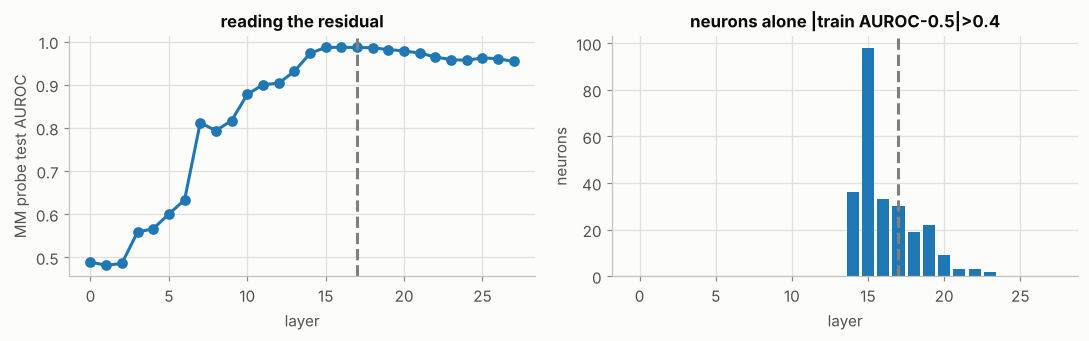

층 12: d′(val) 2.23  MM test 0.903  혼자 가르는 뉴런 0
층 13: d′(val) 2.39  MM test 0.931  혼자 가르는 뉴런 0
층 14: d′(val) 2.90  MM test 0.972  혼자 가르는 뉴런 36
층 15: d′(val) 3.27  MM test 0.986  혼자 가르는 뉴런 98
층 16: d′(val) 3.26  MM test 0.986  혼자 가르는 뉴런 33
층 17: d′(val) 3.34  MM test 0.986  혼자 가르는 뉴런 30
층 18: d′(val) 3.26  MM test 0.985  혼자 가르는 뉴런 19
층 19: d′(val) 3.14  MM test 0.981  혼자 가르는 뉴런 22
층 20: d′(val) 3.04  MM test 0.978  혼자 가르는 뉴런 9
층 21: d′(val) 2.98  MM test 0.973  혼자 가르는 뉴런 3


In [5]:
sp = pl.group_split(df.group.values)
y = df.label.values
N_LAYERS = cfg.num_hidden_layers
E = nl.extract(model, tok, texts, range(N_LAYERS), kinds=("a", "resid", "xhat"))  # cache가 없으면 CPU 1–2분

sweep = []
for l in range(N_LAYERS):
    R, A = E["resid"][l], E["a"][l]
    probe = pl.fit_mass_mean(R[sp.train], y[sp.train])
    au_tr = nl.neuron_aurocs(y[sp.train], A[sp.train])
    sweep.append(dict(layer=l, dval=pl.dprime(probe, R[sp.val], y[sp.val]),
                      mm_test=pl.auroc(y[sp.test], probe.score(R[sp.test])),
                      n_neurons=int((np.abs(au_tr - 0.5) > 0.4).sum())))
LAYER = max(sweep, key=lambda r: r["dval"])["layer"]
print(f"validation d′로 고른 층: {LAYER}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot([r["layer"] for r in sweep], [r["mm_test"] for r in sweep], marker="o")
ax[0].axvline(LAYER, ls="--", c="gray"); ax[0].set(xlabel="layer", ylabel="MM probe test AUROC", title="reading the residual")
ax[1].bar([r["layer"] for r in sweep], [r["n_neurons"] for r in sweep])
ax[1].axvline(LAYER, ls="--", c="gray"); ax[1].set(xlabel="layer", ylabel="neurons", title="neurons alone |train AUROC-0.5|>0.4")
plt.tight_layout(); plt.show()
for r in sweep[12:22]:
    print(f"층 {r['layer']:2d}: d′(val) {r['dval']:.2f}  MM test {r['mm_test']:.3f}  혼자 가르는 뉴런 {r['n_neurons']}")

**✍️ 예측 4.** 고른 층에서 train으로 고른 "혼자 가르는 뉴런"은 몇 개였나(위 출력)? 그중 몇 개가 **test에서도** 0.9 초과 또는 0.1 미만일까? 혼자 가르는 뉴런 중 참에서 커지는 것(AUROC > 0.5)과 거짓에서 커지는 것은 대략 몇 대 몇일까?

#### Cell 06 · train에서 고른 뉴런을 test에서 재기

- **이번 셀의 질문:** 혼자 가르는 뉴런은 새 도시에서도 가르는가?
- **출력에서 볼 것:** train에서 고른 수, 그중 test에서도 기준을 넘는 수, 방향(참에서 큼/거짓에서 큼), 상위 10개의 train·test AUROC.
- **해석 범위:** 같은 도시가 train과 test에 함께 들어가지 않는다. 그래도 같은 문장 틀(The city of X is in Y.)이라 '새 문장 형식'에 대한 일반화는 아니다.

In [6]:
A, R, X = E["a"][LAYER], E["resid"][LAYER], E["xhat"][LAYER]
W = nl.mlp_weights(model, LAYER)
au_tr = nl.neuron_aurocs(y[sp.train], A[sp.train])
au_te = nl.neuron_aurocs(y[sp.test], A[sp.test])
strong = np.flatnonzero(np.abs(au_tr - 0.5) > 0.4)
order = np.argsort(-np.abs(au_tr - 0.5))
TOP20 = order[:20]
print(f"train에서 혼자 가르는 뉴런 {len(strong)}개 → 그중 test에서도 기준을 넘는 것 {int((np.abs(au_te[strong] - 0.5) > 0.4).sum())}개")
print(f"방향: 참에서 큼 {int((au_tr[strong] > 0.5).sum())}개, 거짓에서 큼 {int((au_tr[strong] < 0.5).sum())}개")
print("상위 10개  뉴런 번호:", order[:10])
print("          train AUROC:", np.round(au_tr[order[:10]], 3))
print("           test AUROC:", np.round(au_te[order[:10]], 3))

train에서 혼자 가르는 뉴런 30개 → 그중 test에서도 기준을 넘는 것 27개
방향: 참에서 큼 13개, 거짓에서 큼 17개
상위 10개  뉴런 번호: [1327 1560 1526 1278 2335  555  578  753  795 2802]
          train AUROC: [0.035 0.045 0.949 0.059 0.937 0.066 0.066 0.068 0.932 0.93 ]
           test AUROC: [0.034 0.052 0.958 0.062 0.924 0.064 0.081 0.06  0.919 0.945]


## 5. 대조군: 뉴런은 특별한가

"혼자 가르는 뉴런이 수십 개 있다"는 관찰은 **뉴런이라는 좌표축**이 참/거짓에 맞춰져 있다는 뜻일까? 그렇게 말하려면, 같은 공간에서 **아무 축이나** 골랐을 때보다 뉴런 축이 더 잘 갈라야 한다. 1.3.1 ④의 "무작위 방향 대조군"과 같은 생각이다.

[정의] 대조군: 같은 3,072차원 활성 공간의 무작위 단위 방향 $v$ 3,072개. 점수는 $v\cdot a$이다. 뉴런 $i$는 $v = e_i$(표준 기저)인 특별한 경우다.

두 가지 무작위 방향을 쓴다.
- **원래 좌표의 무작위 방향.** 뉴런마다 활성의 크기(분산)가 다르므로, 무작위 방향은 분산이 큰 뉴런에 끌린다.
- **표준화한 좌표의 무작위 방향.** 뉴런마다 train 평균을 빼고 표준편차로 나눈 뒤 무작위 방향을 쓴다. 뉴런 사이의 크기 차이를 지운 대조군이다.

**✍️ 예측 5 (이 권의 핵심).** 원래 좌표의 무작위 방향 3,072개 중 train AUROC가 0.9 초과 또는 0.1 미만인 것은 몇 개일까? 뉴런(Cell 06의 수)보다 많을까 적을까? 표준화한 좌표에서는? 두 결과가 다르면, "뉴런 기저가 참/거짓에 특별하다"는 문장에 대해 무엇을 말할 수 있을까?

#### Cell 07 · 뉴런 vs 무작위 방향

- **이번 셀의 질문:** 같은 공간의 아무 축보다 뉴런 축이 더 잘 가르는가?
- **출력에서 볼 것:** 세 경우(뉴런, 원래 좌표의 무작위, 표준화 좌표의 무작위)의 '혼자 가르는' 수와 $|\mathrm{AUROC}-0.5|$ 분포. 그리고 활성 공간 전체를 쓴 MM probe.
- **해석 범위:** 참/거짓이라는, **우리가 고른 개념 하나**에 대한 비교다. 논문의 주장('뉴런이 하는 일을 짧게 설명할 수 있다')을 직접 시험하지 않는다.

뉴런              : 3,072개 중 혼자 가르는 것 30
무작위 (원래 좌표)     : 3,072개 중 혼자 가르는 것 34
무작위 (표준화 좌표)    : 3,072개 중 혼자 가르는 것 9
활성 공간 전체(3,072차원) MM probe test AUROC 0.990


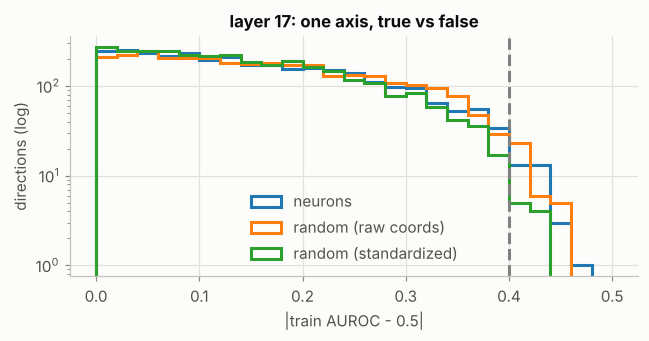

In [7]:
V = nl.random_unit_directions(A.shape[1], A.shape[1], seed=0)          # [3072, 3072] 무작위 단위 방향
au_rand_tr = nl.neuron_aurocs(y[sp.train], A[sp.train] @ V.T)
mu, sd = A[sp.train].mean(0), A[sp.train].std(0) + 1e-6
Z = (A - mu) / sd                                                      # 뉴런마다 표준화
au_randz_tr = nl.neuron_aurocs(y[sp.train], Z[sp.train] @ V.T)

counts = {"뉴런": int((np.abs(au_tr - 0.5) > 0.4).sum()),
          "무작위 (원래 좌표)": int((np.abs(au_rand_tr - 0.5) > 0.4).sum()),
          "무작위 (표준화 좌표)": int((np.abs(au_randz_tr - 0.5) > 0.4).sum())}
for k, v in counts.items():
    print(f"{k:16s}: 3,072개 중 혼자 가르는 것 {v}")
probe_a = pl.fit_mass_mean(A[sp.train], y[sp.train])
print(f"활성 공간 전체(3,072차원) MM probe test AUROC {pl.auroc(y[sp.test], probe_a.score(A[sp.test])):.3f}")

bins = np.linspace(0, 0.5, 26)
plt.figure(figsize=(6, 3.2))
for lab, au in [("neurons", au_tr), ("random (raw coords)", au_rand_tr), ("random (standardized)", au_randz_tr)]:
    plt.hist(np.abs(au - 0.5), bins=bins, histtype="step", lw=2, label=lab)
plt.axvline(0.4, ls="--", c="gray"); plt.yscale("log")
plt.xlabel("|train AUROC - 0.5|"); plt.ylabel("directions (log)"); plt.legend(); plt.title(f"layer {LAYER}: one axis, true vs false")
plt.tight_layout(); plt.show()

**읽는 법.**
- 원래 좌표의 무작위 방향이 뉴런만큼, 또는 그보다 더 많이 혼자 가른다. 참/거짓 정보가 많은 뉴런에 퍼져 있으면(활성 공간 전체의 MM probe가 0.99), 아무 방향이나 그 일부를 읽는다. 1.3.1 ⑦의 "무작위 국가 묶음도 0.99"와 같은 꼴이다. 읽힌다는 것만으로는 그 축이 특별하다는 증거가 못 된다.
- 표준화하면 무작위 방향의 수가 크게 준다. 그러면 뉴런이 더 많다. **판정이 대조군을 무엇으로 정하느냐에 따라 갈린다.** 어느 쪽이 공정한가? 원래 좌표의 무작위 방향은 뉴런의 크기 차이를 그대로 물려받는다. 표준화 좌표는 그 차이를 지우지만 모델이 실제로 쓰는 좌표가 아니다. 이 권에서는 판정을 보류한다(주장 장부).
- 남는 교훈: "X를 혼자 가르는 뉴런이 있다"를 볼 때마다 **같은 공간의 무작위 축은 몇 개나 그런가**를 먼저 묻는다. 이 질문은 ④에서 다시 쓴다. 뉴런 설명의 점수가 좋다면, 무작위 방향에 설명을 붙였을 때의 점수와 비교했는가?

## 6. 읽기, 쓰기, 기여, 필요

참/거짓을 가르는 뉴런이 있다고 하자. 그 뉴런에 대해 다른 질문이 넷 있다.

| 질문 | 재는 것 | 이 권의 셀 |
|---|---|---|
| 읽기: 활성이 참/거짓에 따라 다른가 | 뉴런 AUROC | 06 |
| 쓰기: 쓰는 벡터 $d_i$가 참/거짓 방향을 향하는가 | $\cos(d_i, t)$ | 08 |
| 기여: 이 층의 출력이 참/거짓 방향으로 갈라지는 데 이 뉴런이 얼마나 보태는가 | (참 평균 $a_i$ − 거짓 평균 $a_i$) × $(d_i\cdot \hat t)$ | 09 |
| 필요: 이 뉴런을 끄면 뒤에서 참/거짓을 못 읽게 되는가 | 끈 뒤 probe AUROC | 10 |

[정의] 참/거짓 방향 $t$는 1.3.1처럼 MM probe 방향(참 평균 − 거짓 평균)이다. 쓰기와 비교할 때는 이 층 block 출력의 $t_{\text{resid}}$, 읽기 벡터와 비교할 때는 MLP 입력 $\hat x$ 공간의 $t_{\hat x}$를 쓴다. 뉴런이 읽는 것은 $\hat x$이고 쓰는 곳은 residual이기 때문이다.

[근사] 1,024차원에서 무작위 두 벡터의 $|\cos|$은 평균 약 $\sqrt{2/(\pi\cdot 1024)}\approx 0.025$이다. 비교 기준으로 쓴다(유도는 구멍 장부).

**✍️ 예측 6.** Cell 06의 상위 20개 뉴런(가장 잘 가르는 뉴런)의 쓰기 벡터 $d_i$는 $t_{\text{resid}}$와 $|\cos|$이 평균 얼마일까? 뉴런 3,072개 전체의 평균보다 클까? 읽기 벡터(gate 행, up 행)와 $t_{\hat x}$는?

#### Cell 08 · 읽는 벡터와 쓰는 벡터

- **이번 셀의 질문:** 참/거짓을 가르는 뉴런은 참/거짓 방향을 읽고, 참/거짓 방향으로 쓰는가?
- **출력에서 볼 것:** 상위 20개와 전체 뉴런의 $|\cos|$ 평균과 99% 분위. 상위 20개가 쓰기 $|\cos|$ 순위에서 몇 등인가.
- **해석 범위:** 가중치만 보는 측정이다. 뉴런의 쓰기 벡터와 probe 방향의 각도는, 그 뉴런이 출력에 어떻게 쓰이는지와는 또 다른 질문이다(⑤).

In [8]:
t_resid = pl.fit_mass_mean(R[sp.train], y[sp.train]).direction
t_xhat = pl.fit_mass_mean(X[sp.train], y[sp.train]).direction
cos_write = nl.cos_cols(t_resid, W["W_down"], axis=0)    # cos(d_i, t_resid), [F]
cos_gate = nl.cos_cols(t_xhat, W["W_gate"], axis=1)      # cos(gate 행 i, t_x̂)
cos_up = nl.cos_cols(t_xhat, W["W_up"], axis=1)          # cos(up 행 i, t_x̂)
rows = {}
for name, c in [("쓰기 d_i  vs t_resid", cos_write), ("읽기 gate vs t_x̂", cos_gate), ("읽기 up   vs t_x̂", cos_up)]:
    rows[name] = dict(top20=float(np.abs(c[TOP20]).mean()), all=float(np.abs(c).mean()), p99=float(np.quantile(np.abs(c), .99)))
    print(f"{name}: 상위 20개 |cos| 평균 {rows[name]['top20']:.3f}   전체 평균 {rows[name]['all']:.3f}   전체 99% 분위 {rows[name]['p99']:.3f}")
rank_write = np.argsort(np.argsort(-np.abs(cos_write)))
print("상위 20개가 쓰기 |cos| 순위에서 몇 등인가 (3,072등 중):", np.sort(rank_write[TOP20]) + 1)

쓰기 d_i  vs t_resid: 상위 20개 |cos| 평균 0.027   전체 평균 0.028   전체 99% 분위 0.104
읽기 gate vs t_x̂: 상위 20개 |cos| 평균 0.048   전체 평균 0.023   전체 99% 분위 0.081
읽기 up   vs t_x̂: 상위 20개 |cos| 평균 0.060   전체 평균 0.024   전체 99% 분위 0.078


상위 20개가 쓰기 |cos| 순위에서 몇 등인가 (3,072등 중): [  58  253  346  391  414  487 1107 1207 1646 1792 2139 2252 2330 2427
 2493 2602 2844 2845 2960 2964]


**읽는 법.** 읽기 쪽은 상위 20개가 평균의 약 두 배로 $t_{\hat x}$를 향한다. 그래도 $|\cos|$ 0.05–0.06이라 작다. 뉴런은 참/거짓 방향 하나가 아니라, 그 방향과 조금 겹치는 다른 무언가를 읽는다. 쓰기 쪽은 상위 20개가 **평균과 같다**. 순위도 58등부터 2,964등까지 흩어져 있다. 이 뉴런들은 참/거짓을 읽지만 참/거짓 방향으로 쓰지 않는다. 그러면 무엇을 쓰는가? 이 권은 답하지 않는다. 그것이 ④⑤의 질문이다.

1.3.1 ⑥에서 배운 것이 여기서 다시 나온다. 뉴런 하나의 AUROC는 활성 공간의 **한 축 위의 그림자**만 말한다. 그 뉴런이 residual 어디로 쓰는지는 말하지 않는다.

**✍️ 예측 7.** 이 층의 MLP 출력이 $t_{\text{resid}}$ 방향으로 참과 거짓을 벌리는 양을 뉴런별로 나눈다([대수]: $\sum_i \Delta\bar a_i\,(d_i\cdot\hat t)$, $\Delta\bar a_i$ = 참 평균 − 거짓 평균). 그 몫이 가장 큰 뉴런 20개는 Cell 06의 상위 20개(가장 잘 가르는 뉴런)와 몇 개나 겹칠까?

#### Cell 09 · 가르는 뉴런 vs 보태는 뉴런

- **이번 셀의 질문:** 참/거짓 차이에 가장 많이 보태는 뉴런은 가장 잘 가르는 뉴런인가?
- **출력에서 볼 것:** 몫 상위 20개와 가르기 상위 20개의 겹침 수, 몫의 합, 상위 20개의 몫 비율, 그리고 같은 방향으로 잰 residual 전체의 참−거짓 차이.
- **해석 범위:** [대수] 이 층 MLP 하나의 몫이다. residual의 차이는 앞의 모든 층(attention, MLP)이 쌓은 것이라 MLP 몫의 합보다 크다.

In [9]:
t_hat = t_resid / np.linalg.norm(t_resid)
delta_a = A[y == 1].mean(0) - A[y == 0].mean(0)          # 뉴런별 참 평균 − 거짓 평균, [F]
share = delta_a * (W["W_down"].T @ t_hat)                # 뉴런별 몫, [F]. 합 = MLP 출력의 참−거짓 차이 · t̂
TOP20_share = np.argsort(-np.abs(share))[:20]
print(f"몫 상위 20개와 가르기 상위 20개의 겹침: {len(set(TOP20_share) & set(TOP20))}개")
print(f"이 층 MLP 몫의 합 {share.sum():.2f},  그중 몫 상위 20개 {share[TOP20_share].sum() / share.sum():.0%}")
print(f"가르기 상위 20개의 몫 합 {share[TOP20].sum():.2f}")
print(f"같은 방향으로 잰 residual 전체의 참−거짓 차이 {(R[y == 1].mean(0) - R[y == 0].mean(0)) @ t_hat:.2f}")
print("몫 상위 5개의 train AUROC:", np.round(au_tr[TOP20_share[:5]], 3))

몫 상위 20개와 가르기 상위 20개의 겹침: 1개
이 층 MLP 몫의 합 3.33,  그중 몫 상위 20개 48%
가르기 상위 20개의 몫 합 0.09
같은 방향으로 잰 residual 전체의 참−거짓 차이 12.65
몫 상위 5개의 train AUROC: [0.109 0.208 0.67  0.949 0.103]


**읽는 법.** AUROC는 **순위**(참과 거짓이 겹치지 않는가)를 재고, 몫은 **크기와 방향**(평균 차이 × 쓰기 투영)을 잰다. 잘 가르지만 작게 쓰거나 다른 방향으로 쓰는 뉴런은 몫이 작다. 반대로 평균 차이가 작아도 $t$ 방향으로 크게 쓰는 뉴런은 몫이 크다. "이 개념의 뉴런"을 고를 때 어느 기준을 썼는지에 따라 다른 뉴런이 나온다.

[근사] direct logit attribution(뉴런의 쓰기 벡터를 바로 unembedding에 곱하기)은 이 층에서는 쓰지 않았다. 17층 뒤에 10층이 더 있어서, 쓰기 벡터가 그대로 출력까지 가지 않는다. 시험 삼아 해 보면 상위 뉴런이 올리는 token이 여러 언어의 조각으로 나와 해석이 안 된다(`nl.logit_lens_of_vector`). 1.5.3 §3처럼 마지막 층 근처에서만 쓸 만하다.

**✍️ 예측 8.** 이 층에서 가장 잘 가르는 뉴런 30개를 0으로 끈다(모든 token 위치에서). 그러면 3층 뒤(20층) residual에서 참/거짓 probe의 test AUROC는? (가) 끄기 전에 학습한 probe를 그대로 쓸 때, (나) 끈 뒤에 다시 학습할 때. 대조군으로 무작위 30개를 끄면? 이 층의 MLP 뉴런 **전부**(3,072개)를 끄면?

#### Cell 10 · 끄기: 이 뉴런들이 필요한가

- **이번 셀의 질문:** 가장 잘 가르는 뉴런을 끄면 뒤에서 참/거짓을 못 읽게 되는가?
- **출력에서 볼 것:** 네 조건(끄기 전, 상위 30개, 무작위 30개, 전부)의 고정 probe와 다시 학습한 probe의 AUROC, 그리고 20층 residual이 평균 얼마나 움직였나.
- **해석 범위:** '뒤에서 probe로 읽을 수 있는가'만 잰다. 모델의 판단(출력)이 바뀌는지는 재지 않았다. 판단에 대한 필요는 ⑤에서 잰다. 끄는 값은 0(zero ablation)과 train 평균(mean ablation) 둘을 쓴다.

In [10]:
LATER = LAYER + 3
R_later = E["resid"][LATER]
probe_later = pl.fit_mass_mean(R_later[sp.train], y[sp.train])
top30 = order[:30]
rand30 = np.random.default_rng(0).choice(A.shape[1], 30, replace=False)
mean_a = A[sp.train].mean(0)
ablation = {"끄기 전": dict(fixed=pl.auroc(y[sp.test], probe_later.score(R_later[sp.test])), refit=None, shift=0.0)}
for name, ids, vals in [("상위 30개 → 0", top30, 0.0), ("상위 30개 → 평균", top30, mean_a[top30]),
                        ("무작위 30개 → 0", rand30, 0.0), ("전부 3,072개 → 0", np.arange(A.shape[1]), 0.0)]:
    with nl.set_neurons(model, LAYER, ids, vals):
        Rx = nl.extract(model, tok, texts, [LATER], kinds=("resid",), use_cache=False)["resid"][LATER]
    refit = pl.fit_mass_mean(Rx[sp.train], y[sp.train])
    ablation[name] = dict(fixed=pl.auroc(y[sp.test], probe_later.score(Rx[sp.test])),
                          refit=pl.auroc(y[sp.test], refit.score(Rx[sp.test])),
                          shift=float(np.linalg.norm(Rx - R_later, axis=1).mean()))
print(f"{LAYER}층을 끄고 {LATER}층에서 읽기")
for k, v in ablation.items():
    refit = "  —  " if v["refit"] is None else f"{v['refit']:.3f}"
    print(f"  {k:14s}: 고정 probe {v['fixed']:.3f}   다시 학습 {refit}   residual 이동 평균 {v['shift']:.1f}  (|residual| 평균 {np.linalg.norm(R_later, axis=1).mean():.0f})")

17층을 끄고 20층에서 읽기
  끄기 전          : 고정 probe 0.978   다시 학습   —     residual 이동 평균 0.0  (|residual| 평균 197)
  상위 30개 → 0    : 고정 probe 0.978   다시 학습 0.978   residual 이동 평균 2.1  (|residual| 평균 197)
  상위 30개 → 평균   : 고정 probe 0.978   다시 학습 0.978   residual 이동 평균 1.5  (|residual| 평균 197)
  무작위 30개 → 0   : 고정 probe 0.978   다시 학습 0.978   residual 이동 평균 2.6  (|residual| 평균 197)
  전부 3,072개 → 0 : 고정 probe 0.976   다시 학습 0.975   residual 이동 평균 46.8  (|residual| 평균 197)


**읽는 법.** 가장 잘 가르는 30개를 꺼도, 무작위 30개를 꺼도, 이 층 MLP를 통째로 꺼도 3층 뒤의 참/거짓 가독성은 거의 그대로다. 통째로 끄면 residual이 크게 움직이는데도 그렇다. 참/거짓 정보는 이 층 MLP 말고도 residual에 이미 있고, 다른 경로가 그것을 뒤로 나른다.

이것이 1.3.1 ⑦의 "읽힘 ≠ 쓰임"의 뉴런판이다. **이 뉴런들에서 참/거짓이 읽힌다**는 것과 **모델이 이 뉴런들을 필요로 한다**는 것은 다른 주장이다. 이 권의 숫자는 앞의 것만 지지한다.

## 주장 장부

In [11]:
ledger = [
    ("SwiGLU 뉴런의 쓰기는 뉴런별 합 Σ a_i d_i로 정확히 나뉜다", "유지 [대수]", "Cell 02: 차이가 반올림 수준"),
    ("'양의 극'이라는 이름은 관례이고, |a|의 크기는 뉴런 사이에 바로 비교되지 않는다", "유지 [대수]", "Cell 04: 대칭을 적용해도 logit이 같다"),
    ("이 데이터에서 강한 활성의 사분면 비율이 논문과 같다", "기각 (조건이 달라 논문 반박은 아님)", "Cell 03: Q3, Q4가 훨씬 많고, Q3이 주가 되는 뉴런 무리가 따로 있다"),
    (f"{LAYER}층에 참/거짓을 혼자 가르는 뉴런이 있고 새 도시에서도 가른다", "관찰됨", f"Cell 06: train {len(strong)}개 중 test에서도 {int((np.abs(au_te[strong] - 0.5) > 0.4).sum())}개"),
    ("뉴런 기저가 참/거짓에 특별하다", "보류", f"Cell 07: 무작위 방향 원래 좌표 {counts['무작위 (원래 좌표)']}개, 표준화 {counts['무작위 (표준화 좌표)']}개, 뉴런 {counts['뉴런']}개"),
    ("가장 잘 가르는 뉴런이 참/거짓 방향으로 쓴다", "기각", "Cell 08: 쓰기 |cos|이 전체 평균과 같다"),
    ("가장 잘 가르는 뉴런이 참/거짓 차이에 가장 많이 보탠다", "기각", f"Cell 09: 상위 20개끼리 겹침 {len(set(TOP20_share) & set(TOP20))}개"),
    (f"{LAYER}층 MLP가 {LATER}층의 참/거짓 가독성에 필요하다", "기각", f"Cell 10: 전부 꺼도 {ablation['전부 3,072개 → 0']['fixed']:.3f}"),
]
for claim, status, ev in ledger:
    print(f"[{status}] {claim}\n    근거: {ev}")

nl.save_results("01_anatomy", dict(
    model=nl.DEFAULT_MODEL, revision=nl.DEFAULT_REVISION, layer=LAYER, later_layer=LATER,
    sweep=sweep, quadrant_top100_mean=quad[100].mean(1), quadrant_top800_mean=quad[800].mean(1), quadrant_all=q_all,
    n_strong_train=len(strong), n_strong_test_kept=int((np.abs(au_te[strong] - 0.5) > 0.4).sum()),
    control_counts=counts, cos=rows, share_overlap=len(set(TOP20_share) & set(TOP20)), ablation=ablation,
    ledger=ledger))
print("\nresults/01_anatomy.json 저장")

[유지 [대수]] SwiGLU 뉴런의 쓰기는 뉴런별 합 Σ a_i d_i로 정확히 나뉜다
    근거: Cell 02: 차이가 반올림 수준
[유지 [대수]] '양의 극'이라는 이름은 관례이고, |a|의 크기는 뉴런 사이에 바로 비교되지 않는다
    근거: Cell 04: 대칭을 적용해도 logit이 같다
[기각 (조건이 달라 논문 반박은 아님)] 이 데이터에서 강한 활성의 사분면 비율이 논문과 같다
    근거: Cell 03: Q3, Q4가 훨씬 많고, Q3이 주가 되는 뉴런 무리가 따로 있다
[관찰됨] 17층에 참/거짓을 혼자 가르는 뉴런이 있고 새 도시에서도 가른다
    근거: Cell 06: train 30개 중 test에서도 27개
[보류] 뉴런 기저가 참/거짓에 특별하다
    근거: Cell 07: 무작위 방향 원래 좌표 34개, 표준화 9개, 뉴런 30개
[기각] 가장 잘 가르는 뉴런이 참/거짓 방향으로 쓴다
    근거: Cell 08: 쓰기 |cos|이 전체 평균과 같다
[기각] 가장 잘 가르는 뉴런이 참/거짓 차이에 가장 많이 보탠다
    근거: Cell 09: 상위 20개끼리 겹침 1개
[기각] 17층 MLP가 20층의 참/거짓 가독성에 필요하다
    근거: Cell 10: 전부 꺼도 0.976

results/01_anatomy.json 저장


## 구멍 장부

건너뛴 것과, 그것이 다시 나오는 곳이다. 지금 모르는 채로 넘어가도 이 권의 결론에는 영향이 없다.

| 건너뛴 것 | 지금 알아 둘 한 줄 | 다시 나오는 곳 |
|---|---|---|
| RMSNorm | 뉴런이 읽는 $\hat x$는 residual을 크기로 나누고 원소별 배율 $\gamma$를 곱한 것이다. 그래서 같은 방향이라도 residual의 크기에 따라 $g, u$가 달라진다 | ⑤ 입력 분해 (논문은 RMSNorm 배율을 실제 값으로 고정하고 뉴런 입력을 정확히 나눈다) |
| attention | $\hat x$에는 attention이 쓴 것도 들어 있다 | ⑤ patching |
| $\lvert\cos\rvert$ 기준선 0.025의 유도 | 고차원에서 무작위 두 벡터는 거의 직교한다 | 부록: 내적 (LADR 6장 전에 필요한 만큼) |
| 분위수 p97/3 | 뉴런마다 자기 활성 분포의 3% 아래와 97% 위를 "강한 활성"으로 본다 | ③ |
| top-K의 기준 | 논문은 $|a|$(MoE에서는 router weight를 곱한 값)로 고른다. 쓰기 크기 $|a|\,\lVert d_i\rVert$와 다를 수 있다 | ③ 첫 실험 |
| MoE와 routed neuron | 토큰마다 일부 전문가 MLP만 쓰는 구조. 이 모델에는 없다 | 정의만 |
| 판단에 대한 필요 | 이 권은 probe 가독성만 쟀다 | ⑤ |
| 무작위 방향 대조군의 공정성 | 원래 좌표와 표준화 좌표가 다른 답을 냈다 | ② 특권 기저(privileged basis) |

## 다음 권

② **상대 이론**은 "왜 다들 뉴런은 섞여 있다고 믿었나"를 장난감 모델로 직접 돌려 본다. Cell 07에서 판정을 보류한 질문이 거기서 이름을 얻는다. **특권 기저**: 어떤 좌표축이 다른 방향과 다르게 취급되는 이유는 무엇인가. 답의 실마리는 이 권 Cell 02의 식에 있다. SiLU는 좌표마다 따로 걸린다.